In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mahakkhetan/e-commerce-returns/sample_submission.csv
/kaggle/input/datasets/mahakkhetan/e-commerce-returns/test (1).csv
/kaggle/input/datasets/mahakkhetan/e-commerce-returns/train (2).csv


In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/mahakkhetan/e-commerce-returns/sample_submission.csv
/kaggle/input/datasets/mahakkhetan/e-commerce-returns/test (1).csv
/kaggle/input/datasets/mahakkhetan/e-commerce-returns/train (2).csv


In [5]:

import pandas as pd
import os

DATA_DIR = "/kaggle/input/datasets/mahakkhetan/e-commerce-returns"

train_df = pd.read_csv(os.path.join(DATA_DIR, "train (2).csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test (1).csv"))
sample_submission = pd.read_csv(
    os.path.join(DATA_DIR, "sample_submission.csv")
)

print("TRAIN SHAPE:", train_df.shape)
print("TEST SHAPE:", test_df.shape)
print("SAMPLE SUBMISSION SHAPE:", sample_submission.shape)

print("\nTRAIN DATA:")
display(train_df.head())

print("\nTEST DATA:")
display(test_df.head())

print("\nSAMPLE SUBMISSION:")
display(sample_submission.head())


TRAIN SHAPE: (200000, 16)
TEST SHAPE: (50000, 15)
SAMPLE SUBMISSION SHAPE: (50000, 2)

TRAIN DATA:


,customer_age,product_price,discount_percent,product_rating,past_purchase_count,past_return_rate,delivery_delay_days,session_length_minutes,num_product_views,device_type,product_category,shipping_method,payment_method,used_coupon,returned,order_id
0,25,11.666137,43.559601,1.933533,8,0.331408,-0.089637,3.273029,26,tablet,sports,express,paypal,1,0,75381
1,76,31.378967,66.526039,0.690237,9,0.105203,3.639277,130.513123,8,mobile,electronics,standard,credit_card,1,0,65569
2,40,25.460603,20.762374,2.347620,14,0.236683,0.294060,92.780917,-2,desktop,toys,express,credit_card,0,0,163473
3,62,13.517170,25.669260,2.033596,9,0.410038,1.683333,103.004177,7,mobile,clothing,express,apple_pay,0,0,90518
4,51,75.771311,15.527927,4.907556,9,0.123565,-0.153691,100.752658,6,mobile,electronics,standard,credit_card,1,0,138866



TEST DATA:


,customer_age,product_price,discount_percent,product_rating,past_purchase_count,past_return_rate,delivery_delay_days,session_length_minutes,num_product_views,device_type,product_category,shipping_method,payment_method,used_coupon,order_id
0,76,27.219041,33.956530,3.407683,8,0.360088,-0.048753,103.640356,8,mobile,electronics,standard,apple_pay,1,38683
1,46,12.697689,73.475657,1.292020,7,0.351900,0.194206,128.874257,4,tablet,sports,express,paypal,0,64939
2,82,124.202686,27.889864,4.905273,8,0.176939,1.487607,48.277979,7,tablet,electronics,standard,debit_card,1,3954
3,61,116.043805,25.492571,1.925561,7,0.241565,-3.388567,49.545443,18,tablet,beauty,standard,apple_pay,1,120374
4,61,-3.319434,52.672125,1.843536,9,0.332132,1.650511,65.097249,-3,mobile,beauty,standard,debit_card,1,172861



SAMPLE SUBMISSION:


,ID,returned
0,38683,0
1,64939,0
2,3954,0
3,120374,0
4,172861,0


In [6]:

print("TRAIN COLUMNS:")
print(train_df.columns.tolist())

print("\nDATA TYPES:")
print(train_df.dtypes)

print("\nMISSING VALUES:")
display(train_df.isnull().sum())

print("\nDUPLICATE ROWS:", train_df.duplicated().sum())

if "returned" in train_df.columns:
    print("\nRETURN DISTRIBUTION:")
    display(train_df["returned"].value_counts(dropna=False))
    display(train_df["returned"].value_counts(normalize=True, dropna=False))


TRAIN COLUMNS:
['customer_age', 'product_price', 'discount_percent', 'product_rating', 'past_purchase_count', 'past_return_rate', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'device_type', 'product_category', 'shipping_method', 'payment_method', 'used_coupon', 'returned', 'order_id']

DATA TYPES:
customer_age                int64
product_price             float64
discount_percent          float64
product_rating            float64
past_purchase_count         int64
past_return_rate          float64
delivery_delay_days       float64
session_length_minutes    float64
num_product_views           int64
device_type                object
product_category           object
shipping_method            object
payment_method             object
used_coupon                 int64
returned                    int64
order_id                    int64
dtype: object

MISSING VALUES:


customer_age              0
product_price             0
discount_percent          0
product_rating            0
past_purchase_count       0
past_return_rate          0
delivery_delay_days       0
session_length_minutes    0
num_product_views         0
device_type               0
product_category          0
shipping_method           0
payment_method            0
used_coupon               0
returned                  0
order_id                  0
dtype: int64


DUPLICATE ROWS: 0

RETURN DISTRIBUTION:


returned
0    105081
1     94919
Name: count, dtype: int64

returned
0    0.525405
1    0.474595
Name: proportion, dtype: float64

In [7]:

# 1. Check the complete feature list
print("TRAIN-TEST COLUMN DIFFERENCES")
print("Train only:", sorted(set(train_df.columns) - set(test_df.columns)))
print("Test only:", sorted(set(test_df.columns) - set(train_df.columns)))

# 2. Inspect numerical ranges
numeric_cols = train_df.select_dtypes(include="number").columns

print("\nNUMERICAL SUMMARY")
display(train_df[numeric_cols].describe().T.round(3))

# 3. Check suspicious values
checks = {
    "Negative product prices": train_df["product_price"] < 0,
    "Negative discounts": train_df["discount_percent"] < 0,
    "Discounts above 100%": train_df["discount_percent"] > 100,
    "Negative product ratings": train_df["product_rating"] < 0,
    "Ratings above 5": train_df["product_rating"] > 5,
    "Negative delivery delays": train_df["delivery_delay_days"] < 0,
    "Negative session lengths": train_df["session_length_minutes"] < 0,
    "Negative product views": train_df["num_product_views"] < 0,
    "Negative customer ages": train_df["customer_age"] < 0,
}

print("\nSUSPICIOUS VALUE COUNTS")
for name, condition in checks.items():
    print(f"{name}: {condition.sum()}")

# 4. Check IDs
print("\nORDER ID ANALYSIS")
print("Unique train order IDs:", train_df["order_id"].nunique())
print("Duplicate train order IDs:", train_df["order_id"].duplicated().sum())

if "order_id" in test_df.columns:
    print("Unique test order IDs:", test_df["order_id"].nunique())
    print(
        "Train-test order ID overlap:",
        train_df["order_id"].isin(test_df["order_id"]).sum()
    )

# 5. Inspect categorical features
categorical_cols = train_df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}:")
    display(train_df[col].value_counts(dropna=False).head(15))


TRAIN-TEST COLUMN DIFFERENCES
Train only: ['returned']
Test only: []

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
customer_age,200000.0,56.480,17.953,10.000,44.000,58.000,72.000,87.000
product_price,200000.0,37.984,45.627,-183.292,6.877,24.461,53.356,855.079
discount_percent,200000.0,42.872,21.510,-7.541,25.849,42.945,62.642,78.792
product_rating,200000.0,2.813,1.220,0.445,1.789,2.819,3.810,5.453
past_purchase_count,200000.0,9.620,3.140,1.000,8.000,9.000,10.000,26.000
past_return_rate,200000.0,0.215,0.137,-0.061,0.118,0.191,0.282,0.866
delivery_delay_days,200000.0,0.625,2.331,-9.050,-0.752,0.519,1.897,7.961
session_length_minutes,200000.0,77.406,36.394,-11.010,48.995,81.562,108.209,137.653
num_product_views,200000.0,14.654,12.659,-5.000,3.000,13.000,25.000,44.000
used_coupon,200000.0,0.615,0.487,0.000,0.000,1.000,1.000,1.000



SUSPICIOUS VALUE COUNTS
Negative product prices: 27285
Negative discounts: 1686
Discounts above 100%: 0
Negative product ratings: 0
Ratings above 5: 3831
Negative delivery delays: 78564
Negative session lengths: 1487
Negative product views: 21443
Negative customer ages: 0

ORDER ID ANALYSIS
Unique train order IDs: 200000
Duplicate train order IDs: 0
Unique test order IDs: 50000
Train-test order ID overlap: 0

device_type:


device_type
mobile     109371
desktop     48903
tablet      41726
Name: count, dtype: int64


product_category:


product_category
toys           48287
beauty         37100
electronics    36092
home           31839
clothing       23913
sports         22769
Name: count, dtype: int64


shipping_method:


shipping_method
standard    131311
express      53088
same_day     15601
Name: count, dtype: int64


payment_method:


payment_method
debit_card     56667
credit_card    54743
apple_pay      47518
paypal         41072
Name: count, dtype: int64

In [8]:
# Install PySpark
%pip install pyspark

Note: you may need to restart the kernel to use updated packages.


In [9]:

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("ReturnSense")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark application:", spark.sparkContext.appName)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/27 08:25:49 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.0.4
Spark application: ReturnSense


In [10]:
from pathlib import Path

DATA_DIR = "/kaggle/input/datasets/mahakkhetan/e-commerce-returns"

train_path = f"{DATA_DIR}/train (2).csv"
test_path = f"{DATA_DIR}/test (1).csv"
submission_path = f"{DATA_DIR}/sample_submission.csv"

train_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(train_path)
)

test_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(test_path)
)

submission_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(submission_path)
)

print("Training rows:", train_spark.count())
print("Test rows:", test_spark.count())

train_spark.printSchema()
train_spark.show(5, truncate=False)


Training rows: 200000
Test rows: 50000
root
 |-- customer_age: integer (nullable = true)
 |-- product_price: double (nullable = true)
 |-- discount_percent: double (nullable = true)
 |-- product_rating: double (nullable = true)
 |-- past_purchase_count: integer (nullable = true)
 |-- past_return_rate: double (nullable = true)
 |-- delivery_delay_days: double (nullable = true)
 |-- session_length_minutes: double (nullable = true)
 |-- num_product_views: integer (nullable = true)
 |-- device_type: string (nullable = true)
 |-- product_category: string (nullable = true)
 |-- shipping_method: string (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- used_coupon: integer (nullable = true)
 |-- returned: integer (nullable = true)
 |-- order_id: integer (nullable = true)

+------------+------------------+------------------+------------------+-------------------+-------------------+--------------------+----------------------+-----------------+-----------+----------------+----

In [11]:

from pyspark.sql import functions as F
from pyspark.sql.types import NumericType

# Identify numeric columns using the Spark schema
numeric_cols = [
    field.name
    for field in train_spark.schema.fields
    if isinstance(field.dataType, NumericType)
]

# Count nulls in every column, and NaN only in numeric columns
missing_exprs = []

for field in train_spark.schema.fields:
    c = field.name

    if isinstance(field.dataType, NumericType):
        missing_exprs.append(
            F.sum(
                F.when(
                    F.col(c).isNull() | F.isnan(F.col(c)),
                    1
                ).otherwise(0)
            ).alias(c)
        )
    else:
        
        missing_exprs.append(
            F.sum(
                F.when(F.col(c).isNull(), 1).otherwise(0)
            ).alias(c)
        )

print("TRAIN ROWS:", train_spark.count())
print("TEST ROWS:", test_spark.count())

print("\nMISSING VALUES PER COLUMN:")
train_spark.select(*missing_exprs).show(truncate=False)


TRAIN ROWS: 200000
TEST ROWS: 50000

MISSING VALUES PER COLUMN:


+------------+-------------+----------------+--------------+-------------------+----------------+-------------------+----------------------+-----------------+-----------+----------------+---------------+--------------+-----------+--------+--------+
|customer_age|product_price|discount_percent|product_rating|past_purchase_count|past_return_rate|delivery_delay_days|session_length_minutes|num_product_views|device_type|product_category|shipping_method|payment_method|used_coupon|returned|order_id|
+------------+-------------+----------------+--------------+-------------------+----------------+-------------------+----------------------+-----------------+-----------+----------------+---------------+--------------+-----------+--------+--------+
|0           |0            |0               |0             |0                  |0               |0                  |0                     |0                |0          |0               |0              |0             |0          |0       |0       |
+---

In [12]:

checks = {
    "negative_product_price": F.col("product_price") < 0,
    "negative_discount": F.col("discount_percent") < 0,
    "discount_above_100": F.col("discount_percent") > 100,
    "rating_below_0": F.col("product_rating") < 0,
    "rating_above_5": F.col("product_rating") > 5,
    "negative_session_length": F.col("session_length_minutes") < 0,
    "negative_product_views": F.col("num_product_views") < 0,
    "negative_customer_age": F.col("customer_age") < 0,
}

for name, condition in checks.items():
    count = train_spark.filter(condition).count()
    print(f"{name}: {count}")

print("Duplicate order IDs:",
      train_spark.groupBy("order_id")
      .count()
      .filter(F.col("count") > 1)
      .count())


negative_product_price: 27285
negative_discount: 1686


discount_above_100: 0
rating_below_0: 0
rating_above_5: 3831
negative_session_length: 1487
negative_product_views: 21443
negative_customer_age: 0


Duplicate order IDs: 0


In [13]:

from pyspark.sql import functions as F

# Remove exact duplicate rows only
train_clean = train_spark.dropDuplicates()
test_clean = test_spark.dropDuplicates()

# Keep records with valid core numerical values
train_condition = (
    (F.col("product_price") >= 0) &
    (F.col("discount_percent").between(0, 100)) &
    (F.col("product_rating").between(0, 5)) &
    (F.col("customer_age") >= 0) &
    (F.col("session_length_minutes") >= 0) &
    (F.col("num_product_views") >= 0) &
    F.col("returned").isin(0, 1)
)

test_condition = (
    (F.col("product_price") >= 0) &
    (F.col("discount_percent").between(0, 100)) &
    (F.col("product_rating").between(0, 5)) &
    (F.col("customer_age") >= 0) &
    (F.col("session_length_minutes") >= 0) &
    (F.col("num_product_views") >= 0)
)

train_clean = train_clean.filter(train_condition)
test_clean = test_clean.filter(test_condition)

print("Original training rows:", train_spark.count())
print("Cleaned training rows:", train_clean.count())

print("Original test rows:", test_spark.count())
print("Cleaned test rows:", test_clean.count())


Original training rows: 200000


Cleaned training rows: 147922
Original test rows: 50000


Cleaned test rows: 36855


In [14]:

OUTPUT_DIR = "/kaggle/working/returnsense"

(
    train_clean.write
    .mode("overwrite")
    .parquet(f"{OUTPUT_DIR}/train_clean")
)

(
    test_clean.write
    .mode("overwrite")
    .parquet(f"{OUTPUT_DIR}/test_clean")
)

print("Cleaned datasets saved in Parquet format.")


Cleaned datasets saved in Parquet format.


In [15]:

train_parquet = spark.read.parquet(
    f"{OUTPUT_DIR}/train_clean"
)

test_parquet = spark.read.parquet(
    f"{OUTPUT_DIR}/test_clean"
)

print("Training rows after reload:", train_parquet.count())
print("Test rows after reload:", test_parquet.count())

train_parquet.printSchema()


Training rows after reload: 147922
Test rows after reload: 36855
root
 |-- customer_age: integer (nullable = true)
 |-- product_price: double (nullable = true)
 |-- discount_percent: double (nullable = true)
 |-- product_rating: double (nullable = true)
 |-- past_purchase_count: integer (nullable = true)
 |-- past_return_rate: double (nullable = true)
 |-- delivery_delay_days: double (nullable = true)
 |-- session_length_minutes: double (nullable = true)
 |-- num_product_views: integer (nullable = true)
 |-- device_type: string (nullable = true)
 |-- product_category: string (nullable = true)
 |-- shipping_method: string (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- used_coupon: integer (nullable = true)
 |-- returned: integer (nullable = true)
 |-- order_id: integer (nullable = true)



In [16]:

from pyspark.sql import functions as F

# Start from the cleaned data
train_features = train_clean
test_features = test_clean

def add_features(df):
    return (
        df
        # Price and discount behavior
        .withColumn(
            "discount_amount",
            F.col("product_price") * F.col("discount_percent") / 100
        )
        .withColumn(
            "estimated_price_after_discount",
            F.col("product_price") *
            (1 - F.col("discount_percent") / 100)
        )

        # Browsing behavior
        .withColumn(
            "views_per_session_minute",
            F.when(
                F.col("session_length_minutes") > 0,
                F.col("num_product_views") /
                F.col("session_length_minutes")
            ).otherwise(0)
        )

        # Historical return behavior
        .withColumn(
            "historical_return_risk",
            F.when(
                F.col("past_return_rate") >= 0.30, 1
            ).otherwise(0)
        )

        # Purchase history
        .withColumn(
            "frequent_buyer",
            F.when(
                F.col("past_purchase_count") >= 10, 1
            ).otherwise(0)
        )

        # Discount sensitivity
        .withColumn(
            "high_discount",
            F.when(
                F.col("discount_percent") >= 50, 1
            ).otherwise(0)
        )
    )

train_features = add_features(train_features)
test_features = add_features(test_features)

print("Training feature count:", len(train_features.columns))
print("Test feature count:", len(test_features.columns))

train_features.select(
    "product_price",
    "discount_percent",
    "estimated_price_after_discount",
    "session_length_minutes",
    "num_product_views",
    "views_per_session_minute",
    "past_return_rate",
    "historical_return_risk",
    "returned"
).show(10, truncate=False)


Training feature count: 22
Test feature count: 21


+------------------+------------------+------------------------------+----------------------+-----------------+------------------------+--------------------+----------------------+--------+
|product_price     |discount_percent  |estimated_price_after_discount|session_length_minutes|num_product_views|views_per_session_minute|past_return_rate    |historical_return_risk|returned|
+------------------+------------------+------------------------------+----------------------+-----------------+------------------------+--------------------+----------------------+--------+
|5.657471138707976 |65.0463376063044  |1.9774933618447517            |112.08827516758579    |32               |0.2854892713100996      |0.3221281890985657  |1                     |0       |
|91.55239391834398 |16.90204956616833 |76.0781629192518              |71.8586683568879      |18               |0.25049170004936        |0.448188636716093   |1                     |0       |
|6.882517123539827 |21.14241768030142 |5.427386606

In [17]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder

categorical_cols = [
    "device_type",
    "product_category",
    "shipping_method",
    "payment_method"
]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_index",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoder = OneHotEncoder(
    inputCols=[f"{c}_index" for c in categorical_cols],
    outputCols=[f"{c}_ohe" for c in categorical_cols]
)

categorical_pipeline = Pipeline(stages=indexers + [encoder])

categorical_model = categorical_pipeline.fit(train_features)

train_encoded = categorical_model.transform(train_features)
test_encoded = categorical_model.transform(test_features)

train_encoded.select(
    *categorical_cols,
    *[f"{c}_ohe" for c in categorical_cols]
).show(5, truncate=False)


+-----------+----------------+---------------+--------------+---------------+--------------------+-------------------+------------------+
|device_type|product_category|shipping_method|payment_method|device_type_ohe|product_category_ohe|shipping_method_ohe|payment_method_ohe|
+-----------+----------------+---------------+--------------+---------------+--------------------+-------------------+------------------+
|mobile     |beauty          |standard       |apple_pay     |(3,[0],[1.0])  |(6,[1],[1.0])       |(3,[0],[1.0])      |(4,[2],[1.0])     |
|mobile     |home            |standard       |paypal        |(3,[0],[1.0])  |(6,[3],[1.0])       |(3,[0],[1.0])      |(4,[3],[1.0])     |
|tablet     |clothing        |standard       |credit_card   |(3,[2],[1.0])  |(6,[4],[1.0])       |(3,[0],[1.0])      |(4,[1],[1.0])     |
|mobile     |home            |standard       |debit_card    |(3,[0],[1.0])  |(6,[3],[1.0])       |(3,[0],[1.0])      |(4,[0],[1.0])     |
|mobile     |beauty          |stan

In [18]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    Imputer,
    StandardScaler
)
from pyspark.ml.classification import LogisticRegression

numeric_cols = [
    "customer_age",
    "product_price",
    "discount_percent",
    "product_rating",
    "past_purchase_count",
    "past_return_rate",
    "delivery_delay_days",
    "session_length_minutes",
    "num_product_views",
    "used_coupon",
    "discount_amount",
    "estimated_price_after_discount",
    "views_per_session_minute",
    "historical_return_risk",
    "frequent_buyer",
    "high_discount"
]

categorical_cols = [
    "device_type",
    "product_category",
    "shipping_method",
    "payment_method"
]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_index",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoder = OneHotEncoder(
    inputCols=[f"{c}_index" for c in categorical_cols],
    outputCols=[f"{c}_ohe" for c in categorical_cols]
)

imputer = Imputer(
    inputCols=numeric_cols,
    outputCols=[f"{c}_imputed" for c in numeric_cols]
)

assembler = VectorAssembler(
    inputCols=[f"{c}_imputed" for c in numeric_cols] +
              [f"{c}_ohe" for c in categorical_cols],
    outputCol="features",
    handleInvalid="keep"
)

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=False,
    withStd=True
)

lr = LogisticRegression(
    featuresCol="scaled_features",
    labelCol="returned",
    maxIter=50,
    regParam=0.01
)

pipeline = Pipeline(
    stages=indexers + [
        encoder, imputer, assembler, scaler, lr
    ]
)

print("Updated pipeline configured successfully.")


Updated pipeline configured successfully.


In [19]:


# Use the engineered dataframes from Step 8
train_part, valid_part = train_features.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training partition:", train_part.count())
print("Validation partition:", valid_part.count())

lr_model = pipeline.fit(train_part)

print("Logistic Regression training completed!")



Training partition: 118448


Validation partition: 29474


26/10/27 08:26:59 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Logistic Regression training completed!


In [20]:

from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F

predictions = lr_model.transform(valid_part)

evaluator = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

roc_auc = evaluator.evaluate(predictions)

tp = predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 1)
).count()

fp = predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 0)
).count()

fn = predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 1)
).count()

tn = predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 0)
).count()

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
accuracy = (tp + tn) / (tp + tn + fp + fn)

print(f"ROC-AUC:  {roc_auc:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nConfusion matrix:")
print(f"True negatives: {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives: {tp}")


ROC-AUC:  0.5899
Accuracy: 0.5657
Precision:0.5504
Recall:   0.4442
F1-score: 0.4916

Confusion matrix:
True negatives: 10483
False positives: 5057
False negatives: 7744
True positives: 6190


In [21]:

from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F

# Generate predictions on validation data
predictions = lr_model.transform(valid_part)

# ROC-AUC
evaluator = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

roc_auc = evaluator.evaluate(predictions)

# Confusion matrix counts
tp = predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 1)
).count()

fp = predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 0)
).count()

fn = predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 1)
).count()

tn = predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 0)
).count()

# Calculate metrics safely
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
accuracy = (tp + tn) / (tp + tn + fp + fn)

print("=" * 40)
print("RETURNSENSE — BASELINE MODEL RESULTS")
print("=" * 40)
print(f"ROC-AUC:  {roc_auc:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nCONFUSION MATRIX")
print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")


RETURNSENSE — BASELINE MODEL RESULTS
ROC-AUC:  0.5899
Accuracy: 0.5657
Precision:0.5504
Recall:   0.4442
F1-score: 0.4916

CONFUSION MATRIX
True negatives:  10483
False positives: 5057
False negatives: 7744
True positives:  6190


In [22]:

from pyspark.ml import Pipeline
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    Imputer,
    VectorAssembler
)

# Use the same numeric and categorical feature lists
numeric_cols = [
    "customer_age",
    "product_price",
    "discount_percent",
    "product_rating",
    "past_purchase_count",
    "past_return_rate",
    "delivery_delay_days",
    "session_length_minutes",
    "num_product_views",
    "used_coupon",
    "discount_amount",
    "estimated_price_after_discount",
    "views_per_session_minute",
    "historical_return_risk",
    "frequent_buyer",
    "high_discount"
]

categorical_cols = [
    "device_type",
    "product_category",
    "shipping_method",
    "payment_method"
]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_index",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoder = OneHotEncoder(
    inputCols=[f"{c}_index" for c in categorical_cols],
    outputCols=[f"{c}_ohe" for c in categorical_cols]
)

imputer = Imputer(
    inputCols=numeric_cols,
    outputCols=[f"{c}_imputed" for c in numeric_cols]
)

assembler = VectorAssembler(
    inputCols=[f"{c}_imputed" for c in numeric_cols] +
              [f"{c}_ohe" for c in categorical_cols],
    outputCol="features",
    handleInvalid="keep"
)

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="returned",
    numTrees=60,
    maxDepth=8,
    seed=42
)

rf_pipeline = Pipeline(
    stages=indexers + [encoder, imputer, assembler, rf]
)

rf_model = rf_pipeline.fit(train_part)

print("Random Forest training completed!")


26/10/27 08:28:12 WARN DAGScheduler: Broadcasting large task binary with size 1386.2 KiB
26/10/27 08:28:16 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB


Random Forest training completed!


In [23]:

from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F

rf_predictions = rf_model.transform(valid_part)

evaluator = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

rf_auc = evaluator.evaluate(rf_predictions)

tp = rf_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 1)
).count()

fp = rf_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 0)
).count()

fn = rf_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 1)
).count()

tn = rf_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 0)
).count()

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
accuracy = (tp + tn) / (tp + tn + fp + fn)

print("RANDOM FOREST RESULTS")
print(f"ROC-AUC:  {rf_auc:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")


26/10/27 08:28:25 WARN DAGScheduler: Broadcasting large task binary with size 1958.8 KiB
26/10/27 08:28:29 WARN DAGScheduler: Broadcasting large task binary with size 1959.3 KiB
26/10/27 08:28:32 WARN DAGScheduler: Broadcasting large task binary with size 1959.3 KiB
26/10/27 08:28:35 WARN DAGScheduler: Broadcasting large task binary with size 1959.3 KiB
26/10/27 08:28:38 WARN DAGScheduler: Broadcasting large task binary with size 1959.3 KiB


RANDOM FOREST RESULTS
ROC-AUC:  0.5890
Accuracy: 0.5676
Precision:0.5594
Recall:   0.4024
F1-score: 0.4681


In [24]:

import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc,
        "Accuracy": accuracy if False else None
    },
    {
        "Model": "Random Forest",
        "ROC-AUC": rf_auc,
        "Accuracy": None
    }
])

display(comparison)


,Model,ROC-AUC,Accuracy
0,Logistic Regression,0.589938,None
1,Random Forest,0.589015,None


In [25]:

from pyspark.sql import functions as F

# 1. Overall return rate
print("OVERALL RETURN RATE")
train_features.select(
    F.avg(F.col("returned").cast("double")).alias("return_rate")
).show()

# 2. Correlation between numerical features and return outcome
numeric_cols = [
    "customer_age",
    "product_price",
    "discount_percent",
    "product_rating",
    "past_purchase_count",
    "past_return_rate",
    "delivery_delay_days",
    "session_length_minutes",
    "num_product_views",
    "used_coupon",
    "discount_amount",
    "estimated_price_after_discount",
    "views_per_session_minute",
    "historical_return_risk",
    "frequent_buyer",
    "high_discount"
]

print("NUMERIC FEATURE CORRELATIONS WITH RETURNED")

correlations = []

for c in numeric_cols:
    value = train_features.stat.corr(c, "returned")
    correlations.append((c, value))

correlation_df = spark.createDataFrame(
    correlations, ["feature", "correlation"]
)

correlation_df.orderBy(
    F.desc(F.abs(F.col("correlation")))
).show(truncate=False)

# 3. Return rate by categorical features
categorical_cols = [
    "device_type",
    "product_category",
    "shipping_method",
    "payment_method",
    "used_coupon"
]

for c in categorical_cols:
    print(f"\nRETURN RATE BY {c.upper()}")

    train_features.groupBy(c).agg(
        F.count("*").alias("orders"),
        F.avg(F.col("returned").cast("double")).alias("return_rate")
    ).orderBy(
        F.desc("return_rate")
    ).show(20, truncate=False)


OVERALL RETURN RATE


+------------------+
|       return_rate|
+------------------+
|0.4771298386987737|
+------------------+

NUMERIC FEATURE CORRELATIONS WITH RETURNED


+------------------------------+---------------------+
|feature                       |correlation          |
+------------------------------+---------------------+
|used_coupon                   |0.05467075153362124  |
|delivery_delay_days           |-0.02855815325989197 |
|discount_amount               |0.0271177604744087   |
|product_price                 |0.027033633606792437 |
|past_purchase_count           |-0.026528597435476572|
|estimated_price_after_discount|0.02018282748909452  |
|session_length_minutes        |-0.018777180118668836|
|past_return_rate              |0.0183318547786819   |
|num_product_views             |-0.011581565281162309|
|historical_return_risk        |0.011314736832407113 |
|frequent_buyer                |-0.011215581434080754|
|customer_age                  |-0.010911344670483105|
|discount_percent              |0.010293250067339856 |
|product_rating                |0.0059115264400903525|
|views_per_session_minute      |-0.002923799997984699|
|high_disc

+-----------+------+-------------------+
|device_type|orders|return_rate        |
+-----------+------+-------------------+
|desktop    |36018 |0.52226664445555   |
|tablet     |31009 |0.4874713792769841 |
|mobile     |80895 |0.45306879287965884|
+-----------+------+-------------------+


RETURN RATE BY PRODUCT_CATEGORY


+----------------+------+-------------------+
|product_category|orders|return_rate        |
+----------------+------+-------------------+
|clothing        |17623 |0.5337343244623504 |
|toys            |35042 |0.505307916214828  |
|beauty          |27176 |0.49992640565204594|
|sports          |17297 |0.4511186911025033 |
|home            |24451 |0.4461167232424032 |
|electronics     |26333 |0.42410663426119316|
+----------------+------+-------------------+


RETURN RATE BY SHIPPING_METHOD


+---------------+------+------------------+
|shipping_method|orders|return_rate       |
+---------------+------+------------------+
|express        |39806 |0.5331105863437673|
|standard       |96857 |0.4574888753523235|
|same_day       |11259 |0.4481747934985345|
+---------------+------+------------------+


RETURN RATE BY PAYMENT_METHOD


+--------------+------+-------------------+
|payment_method|orders|return_rate        |
+--------------+------+-------------------+
|apple_pay     |35623 |0.523706594054403  |
|credit_card   |40693 |0.48573464723662546|
|paypal        |29701 |0.4565166156021683 |
|debit_card    |41905 |0.4437895239231595 |
+--------------+------+-------------------+


RETURN RATE BY USED_COUPON


+-----------+------+-------------------+
|used_coupon|orders|return_rate        |
+-----------+------+-------------------+
|1          |90919 |0.49875163607166817|
|0          |57003 |0.44264336964721157|
+-----------+------+-------------------+



In [26]:

import pandas as pd

# Extract the trained Random Forest from the pipeline
rf_classifier_model = rf_model.stages[-1]

# Get importance scores for the encoded feature vector
importance_values = rf_classifier_model.featureImportances.toArray()

# Retrieve feature names from Spark's vector metadata
sample_transformed = rf_model.transform(train_part.limit(1))
metadata = sample_transformed.schema["features"].metadata

attributes = metadata.get("ml_attr", {}).get("attrs", {})

feature_names = {}

for attribute_group in attributes.values():
    for attribute in attribute_group:
        feature_names[attribute["idx"]] = attribute["name"]

# Map importance scores to feature names
importance_rows = []

for idx, score in enumerate(importance_values):
    importance_rows.append({
        "feature": feature_names.get(idx, f"feature_{idx}"),
        "importance": float(score)
    })

importance_df = pd.DataFrame(importance_rows)

importance_df = importance_df.sort_values(
    "importance", ascending=False
).reset_index(drop=True)

print("TOP 15 RANDOM FOREST FEATURES")
display(importance_df.head(15).round(5))


TOP 15 RANDOM FOREST FEATURES


,feature,importance
0,shipping_method_ohe_express,0.10463
1,used_coupon_imputed,0.09527
2,past_purchase_count_imputed,0.06921
3,product_category_ohe_electronics,0.06413
4,device_type_ohe_mobile,0.04753
5,delivery_delay_days_imputed,0.04559
6,payment_method_ohe_apple_pay,0.04558
7,device_type_ohe_desktop,0.04318
8,shipping_method_ohe_standard,0.04019
9,product_category_ohe_clothing,0.03661


In [27]:

from pyspark.ml import Pipeline
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    Imputer,
    VectorAssembler
)

numeric_cols = [
    "customer_age",
    "product_price",
    "discount_percent",
    "product_rating",
    "past_purchase_count",
    "past_return_rate",
    "delivery_delay_days",
    "session_length_minutes",
    "num_product_views",
    "used_coupon",
    "discount_amount",
    "estimated_price_after_discount",
    "views_per_session_minute",
    "historical_return_risk",
    "frequent_buyer",
    "high_discount"
]

categorical_cols = [
    "device_type",
    "product_category",
    "shipping_method",
    "payment_method"
]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_index",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoder = OneHotEncoder(
    inputCols=[f"{c}_index" for c in categorical_cols],
    outputCols=[f"{c}_ohe" for c in categorical_cols]
)

imputer = Imputer(
    inputCols=numeric_cols,
    outputCols=[f"{c}_imputed" for c in numeric_cols]
)

assembler = VectorAssembler(
    inputCols=[f"{c}_imputed" for c in numeric_cols] +
              [f"{c}_ohe" for c in categorical_cols],
    outputCol="features",
    handleInvalid="keep"
)

gbt = GBTClassifier(
    featuresCol="features",
    labelCol="returned",
    maxIter=50,
    maxDepth=5,
    seed=42
)

gbt_pipeline = Pipeline(
    stages=indexers + [encoder, imputer, assembler, gbt]
)

gbt_model = gbt_pipeline.fit(train_part)

print("Gradient-Boosted Tree training completed!")


Gradient-Boosted Tree training completed!


In [28]:

from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F

gbt_predictions = gbt_model.transform(valid_part)

auc_evaluator = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

gbt_auc = auc_evaluator.evaluate(gbt_predictions)

tp = gbt_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 1)
).count()

fp = gbt_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 0)
).count()

fn = gbt_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 1)
).count()

tn = gbt_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 0)
).count()

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
accuracy = (tp + tn) / (tp + tn + fp + fn)

print("GRADIENT-BOOSTED TREE RESULTS")
print(f"ROC-AUC:  {gbt_auc:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")


GRADIENT-BOOSTED TREE RESULTS
ROC-AUC:  0.5875
Accuracy: 0.5665
Precision:0.5492
Recall:   0.4638
F1-score: 0.5029


In [29]:

import pandas as pd

model_comparison = pd.DataFrame([
    {"Model": "Logistic Regression", "ROC-AUC": roc_auc},
    {"Model": "Random Forest", "ROC-AUC": rf_auc},
    {"Model": "Gradient-Boosted Trees", "ROC-AUC": gbt_auc}
])

display(
    model_comparison
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
    .round(4)
)


,Model,ROC-AUC
0,Logistic Regression,0.5899
1,Random Forest,0.5890
2,Gradient-Boosted Trees,0.5875


In [30]:

from pyspark.ml.evaluation import BinaryClassificationEvaluator

gbt_predictions = gbt_model.transform(valid_part)

evaluator = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

gbt_auc = evaluator.evaluate(gbt_predictions)

print(f"Logistic Regression ROC-AUC: {roc_auc:.4f}")
print(f"Random Forest ROC-AUC:       {rf_auc:.4f}")
print(f"Gradient-Boosted Trees AUC:  {gbt_auc:.4f}")


Logistic Regression ROC-AUC: 0.5899
Random Forest ROC-AUC:       0.5890
Gradient-Boosted Trees AUC:  0.5875


In [31]:

from pyspark.sql import functions as F

# Analyze return rates across feature ranges
numeric_features = [
    "past_purchase_count",
    "past_return_rate",
    "product_price",
    "discount_percent",
    "session_length_minutes",
    "num_product_views"
]

for col_name in numeric_features:
    print(f"\nRETURN RATE BY {col_name}")

    grouped = (
        train_features
        .withColumn(
            "feature_bucket",
            F.ntile(5).over(
                __import__("pyspark").sql.Window.orderBy(
                    F.col(col_name)
                )
            )
        )
        .groupBy("feature_bucket")
        .agg(
            F.count("*").alias("orders"),
            F.avg(F.col("returned").cast("double")).alias("return_rate"),
            F.avg(col_name).alias("average_feature_value")
        )
        .orderBy("feature_bucket")
    )

    grouped.show(truncate=False)



RETURN RATE BY past_purchase_count


26/10/27 08:30:29 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:29 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:30 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:30 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:31 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:31 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 0

+--------------+------+-------------------+---------------------+
|feature_bucket|orders|return_rate        |average_feature_value|
+--------------+------+-------------------+---------------------+
|1             |29585 |0.5177961804968734 |6.573432482677032    |
|2             |29585 |0.47906033462903497|8.47757309447355     |
|3             |29584 |0.4566995673336939 |9.0                  |
|4             |29584 |0.46045159545700376|9.487696051919956    |
|5             |29584 |0.47164007571660355|14.552460789616008   |
+--------------+------+-------------------+---------------------+


RETURN RATE BY past_return_rate


26/10/27 08:30:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+--------------+------+-------------------+---------------------+
|feature_bucket|orders|return_rate        |average_feature_value|
+--------------+------+-------------------+---------------------+
|1             |29585 |0.4594896062193679 |0.05450793587040962  |
|2             |29585 |0.47334798039547066|0.1294268707885835   |
|3             |29584 |0.4856679286100595 |0.18746767405096196  |
|4             |29584 |0.4789075175770687 |0.25600670753109805  |
|5             |29584 |0.48823688480259597|0.4248061340105798   |
+--------------+------+-------------------+---------------------+


RETURN RATE BY product_price


26/10/27 08:30:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:35 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


... (4 outputs left out)

+--------------+------+-------------------+---------------------+
|feature_bucket|orders|return_rate        |average_feature_value|
+--------------+------+-------------------+---------------------+
|1             |29585 |0.487713368260943  |24.07968913838738    |
|2             |29585 |0.48663173905695456|57.17346294939251    |
|3             |29584 |0.47813007030827476|82.22082276469175    |
|4             |29584 |0.469848566792861  |103.53714376870508   |
|5             |29584 |0.46332477014602486|123.92875887964654   |
+--------------+------+-------------------+---------------------+


RETURN RATE BY num_product_views


26/10/27 08:30:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+--------------+------+-------------------+---------------------+
|feature_bucket|orders|return_rate        |average_feature_value|
+--------------+------+-------------------+---------------------+
|1             |29585 |0.4852797025519689 |1.8                  |
|2             |29585 |0.4765928680074362 |7.213418962311982    |
|3             |29584 |0.47752163331530556|15.142205246078962   |
|4             |29584 |0.4784680908599243 |24.431179015684155   |
|5             |29584 |0.4677866414277988 |34.080482693347754   |
+--------------+------+-------------------+---------------------+



26/10/27 08:30:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:30:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


In [32]:

from pyspark.sql import functions as F

# Compare original and cleaned training data
print("ORIGINAL ROWS:", train_spark.count())
print("CLEANED ROWS:", train_clean.count())
print("REMOVED ROWS:", train_spark.count() - train_clean.count())

# Count how many rows violate each proposed rule
rules = {
    "negative_price": F.col("product_price") < 0,
    "invalid_discount": ~F.col("discount_percent").between(0, 100),
    "invalid_rating": ~F.col("product_rating").between(0, 5),
    "negative_age": F.col("customer_age") < 0,
    "negative_session": F.col("session_length_minutes") < 0,
    "negative_views": F.col("num_product_views") < 0,
    "invalid_target": ~F.col("returned").isin(0, 1)
}

print("\nROWS VIOLATING EACH RULE")
for name, condition in rules.items():
    print(name, train_spark.filter(condition).count())

# Inspect original numerical distributions
print("\nORIGINAL DATA SUMMARY")
train_spark.select(
    "product_price",
    "discount_percent",
    "product_rating",
    "customer_age",
    "delivery_delay_days",
    "session_length_minutes",
    "num_product_views"
).describe().show()

# Inspect the target distribution before cleaning
print("\nORIGINAL TARGET DISTRIBUTION")
train_spark.groupBy("returned").count().show()

print("\nCLEANED TARGET DISTRIBUTION")
train_clean.groupBy("returned").count().show()


ORIGINAL ROWS: 200000


CLEANED ROWS: 147922


REMOVED ROWS: 52078

ROWS VIOLATING EACH RULE
negative_price 27285
invalid_discount 1686
invalid_rating 3831
negative_age 0
negative_session 1487
negative_views 21443
invalid_target 0

ORIGINAL DATA SUMMARY


+-------+-------------------+------------------+------------------+------------------+-------------------+----------------------+------------------+
|summary|      product_price|  discount_percent|    product_rating|      customer_age|delivery_delay_days|session_length_minutes| num_product_views|
+-------+-------------------+------------------+------------------+------------------+-------------------+----------------------+------------------+
|  count|             200000|            200000|            200000|            200000|             200000|                200000|            200000|
|   mean|  37.98423369832799|42.872055973765775|2.8128047408590735|         56.479545| 0.6250502520428115|     77.40613768144267|          14.65445|
| stddev|  45.62688335118343|21.510489628581183| 1.219874263242394|17.952930210177062| 2.3312209433301434|     36.39421572979708|12.659400321483746|
|    min|-183.29209216881821|-7.540832249618946|0.4453416627520195|                10| -9.049981182815271|

+--------+-----+
|returned|count|
+--------+-----+
|       1|70578|
|       0|77344|
+--------+-----+



In [33]:

from pyspark.sql import functions as F

# 1. Compare row counts
print("ORIGINAL TRAIN:", train_spark.count())
print("CLEANED TRAIN:", train_clean.count())
print("ORIGINAL TEST:", test_spark.count())
print("CLEANED TEST:", test_clean.count())

# 2. Check duplicate order IDs
print("\nDUPLICATE TRAIN ORDER IDS:")
train_spark.groupBy("order_id").count().filter(
    F.col("count") > 1
).show(10, truncate=False)

# 3. Check invalid values in original data
checks = {
    "negative_price": F.col("product_price") < 0,
    "discount_out_of_range": ~F.col("discount_percent").between(0, 100),
    "rating_out_of_range": ~F.col("product_rating").between(0, 5),
    "negative_age": F.col("customer_age") < 0,
    "negative_session": F.col("session_length_minutes") < 0,
    "negative_views": F.col("num_product_views") < 0,
}

print("\nINVALID VALUE COUNTS:")
for name, condition in checks.items():
    print(name, train_spark.filter(condition).count())

# 4. Check the target distribution before and after cleaning
print("\nORIGINAL TARGET:")
train_spark.groupBy("returned").count().orderBy("returned").show()

print("\nCLEANED TARGET:")
train_clean.groupBy("returned").count().orderBy("returned").show()

# 5. Confirm test order IDs are retained
print("\nTEST ORDER ID CHECK:")
print("Original test rows:", test_spark.count())
print("Cleaned test rows:", test_clean.count())
print("Original test distinct IDs:", test_spark.select("order_id").distinct().count())
print("Cleaned test distinct IDs:", test_clean.select("order_id").distinct().count())


ORIGINAL TRAIN: 200000


CLEANED TRAIN: 147922
ORIGINAL TEST: 50000
CLEANED TEST: 36855

DUPLICATE TRAIN ORDER IDS:
+--------+-----+
|order_id|count|
+--------+-----+
+--------+-----+


INVALID VALUE COUNTS:
negative_price 27285
discount_out_of_range 1686
rating_out_of_range 3831
negative_age 0
negative_session 1487
negative_views 21443

ORIGINAL TARGET:
+--------+------+
|returned| count|
+--------+------+
|       0|105081|
|       1| 94919|
+--------+------+


CLEANED TARGET:


+--------+-----+
|returned|count|
+--------+-----+
|       0|77344|
|       1|70578|
+--------+-----+


TEST ORDER ID CHECK:
Original test rows: 50000
Cleaned test rows: 36855
Original test distinct IDs: 50000
Cleaned test distinct IDs: 36855


In [34]:

from pyspark.sql import functions as F

# Start again from the ORIGINAL datasets
# Do not use train_clean or test_clean here.

def handle_invalid_values(df, is_train=False):
    out = df

    # Treat negative prices as invalid, pending data documentation
    out = out.withColumn(
        "product_price",
        F.when(F.col("product_price") >= 0, F.col("product_price"))
    )

    # Discounts should be within 0-100%
    out = out.withColumn(
        "discount_percent",
        F.when(
            F.col("discount_percent").between(0, 100),
            F.col("discount_percent")
        )
    )

    # Assuming product ratings use a 0-5 scale
    out = out.withColumn(
        "product_rating",
        F.when(
            F.col("product_rating").between(0, 5),
            F.col("product_rating")
        )
    )

    # Counts and session duration cannot be negative
    out = out.withColumn(
        "num_product_views",
        F.when(F.col("num_product_views") >= 0, F.col("num_product_views"))
    )

    out = out.withColumn(
        "session_length_minutes",
        F.when(
            F.col("session_length_minutes") >= 0,
            F.col("session_length_minutes")
        )
    )

    # Keep delivery delays: negative values may represent early delivery
    return out


train_ready = handle_invalid_values(train_spark, is_train=True)
test_ready = handle_invalid_values(test_spark)

print("Original training rows:", train_spark.count())
print("Prepared training rows:", train_ready.count())

print("Original test rows:", test_spark.count())
print("Prepared test rows:", test_ready.count())

print("Original test IDs:", test_spark.select("order_id").distinct().count())
print("Prepared test IDs:", test_ready.select("order_id").distinct().count())

print("\nInvalid values now represented as null:")
train_ready.select(
    F.sum(F.col("product_price").isNull().cast("int")).alias("invalid_prices"),
    F.sum(F.col("discount_percent").isNull().cast("int")).alias("invalid_discounts"),
    F.sum(F.col("product_rating").isNull().cast("int")).alias("invalid_ratings"),
    F.sum(F.col("num_product_views").isNull().cast("int")).alias("invalid_views"),
    F.sum(F.col("session_length_minutes").isNull().cast("int")).alias("invalid_sessions")
).show()


Original training rows: 200000
Prepared training rows: 200000
Original test rows: 50000
Prepared test rows: 50000
Original test IDs: 50000
Prepared test IDs: 50000

Invalid values now represented as null:
+--------------+-----------------+---------------+-------------+----------------+
|invalid_prices|invalid_discounts|invalid_ratings|invalid_views|invalid_sessions|
+--------------+-----------------+---------------+-------------+----------------+
|         27285|             1686|           3831|        21443|            1487|
+--------------+-----------------+---------------+-------------+----------------+



In [35]:

from pyspark.sql import functions as F

def engineer_features(df):
    return (
        df
        .withColumn(
            "discount_amount",
            F.col("product_price") * F.col("discount_percent") / 100
        )
        .withColumn(
            "estimated_price_after_discount",
            F.col("product_price") *
            (1 - F.col("discount_percent") / 100)
        )
        .withColumn(
            "views_per_session_minute",
            F.when(
                F.col("session_length_minutes") > 0,
                F.col("num_product_views") /
                F.col("session_length_minutes")
            )
        )
        .withColumn(
            "historical_return_risk",
            F.when(F.col("past_return_rate") >= 0.30, 1)
             .otherwise(0)
        )
        .withColumn(
            "frequent_buyer",
            F.when(F.col("past_purchase_count") >= 10, 1)
             .otherwise(0)
        )
        .withColumn(
            "high_discount",
            F.when(F.col("discount_percent") >= 50, 1)
             .otherwise(0)
        )
    )

train_features = engineer_features(train_ready)
test_features = engineer_features(test_ready)

print("Training rows:", train_features.count())
print("Test rows:", test_features.count())

print("Training feature columns:", len(train_features.columns))
print("Test feature columns:", len(test_features.columns))

train_features.select(
    "product_price",
    "discount_percent",
    "estimated_price_after_discount",
    "past_return_rate",
    "views_per_session_minute",
    "returned"
).show(10, truncate=False)


Training rows: 200000
Test rows: 50000
Training feature columns: 22
Test feature columns: 21
+------------------+------------------+------------------------------+-------------------+------------------------+--------+
|product_price     |discount_percent  |estimated_price_after_discount|past_return_rate   |views_per_session_minute|returned|
+------------------+------------------+------------------------------+-------------------+------------------------+--------+
|11.66613697698637 |43.55960142346256 |6.584414208295924             |0.3314077354329958 |7.943712031261397       |0       |
|31.37896692422914 |66.52603939172272 |10.503783027500818            |0.10520314818028009|0.061296518045180895    |0       |
|25.460602652360645|20.76237395935221 |20.17437711737278             |0.23668273564915243|NULL                    |0       |
|13.517169582560214|25.669260342761554|10.047412131440257            |0.41003785809867044|0.06795840887572167     |0       |
|75.77131053568479 |15.527927347

In [36]:

OUTPUT_DIR = "/kaggle/working/returnsense"

(
    train_features.write
    .mode("overwrite")
    .parquet(f"{OUTPUT_DIR}/train_features")
)

(
    test_features.write
    .mode("overwrite")
    .parquet(f"{OUTPUT_DIR}/test_features")
)

print("Feature tables saved successfully.")


Feature tables saved successfully.


In [37]:

train_features_check = spark.read.parquet(
    f"{OUTPUT_DIR}/train_features"
)

test_features_check = spark.read.parquet(
    f"{OUTPUT_DIR}/test_features"
)

print("Saved training rows:", train_features_check.count())
print("Saved test rows:", test_features_check.count())

print(
    "Test order IDs preserved:",
    test_features_check.select("order_id").distinct().count()
)


Saved training rows: 200000
Saved test rows: 50000
Test order IDs preserved: 50000


In [38]:

from pyspark.sql import functions as F

# Split the original training records, not the old cleaned data
train_part, valid_part = train_features.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_part.count())
print("Validation rows:", valid_part.count())

print("Training return rate:")
train_part.select(
    F.avg(F.col("returned").cast("double")).alias("return_rate")
).show()

print("Validation return rate:")
valid_part.select(
    F.avg(F.col("returned").cast("double")).alias("return_rate")
).show()


Training rows: 160100


Validation rows: 39900
Training return rate:


+------------------+
|       return_rate|
+------------------+
|0.4746221111805122|
+------------------+

Validation return rate:


+------------------+
|       return_rate|
+------------------+
|0.4744862155388471|
+------------------+



In [39]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    Imputer,
    VectorAssembler,
    StandardScaler
)
from pyspark.ml.classification import LogisticRegression

numeric_cols = [
    "customer_age",
    "product_price",
    "discount_percent",
    "product_rating",
    "past_purchase_count",
    "past_return_rate",
    "session_length_minutes",
    "num_product_views",
    "used_coupon",
    "discount_amount",
    "estimated_price_after_discount",
    "views_per_session_minute",
    "historical_return_risk",
    "frequent_buyer",
    "high_discount"
]

categorical_cols = [
    "device_type",
    "product_category",
    "shipping_method",
    "payment_method"
]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_index",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoder = OneHotEncoder(
    inputCols=[f"{c}_index" for c in categorical_cols],
    outputCols=[f"{c}_ohe" for c in categorical_cols]
)

imputer = Imputer(
    inputCols=numeric_cols,
    outputCols=[f"{c}_imputed" for c in numeric_cols],
    strategy="median"
)

assembler = VectorAssembler(
    inputCols=[f"{c}_imputed" for c in numeric_cols] +
              [f"{c}_ohe" for c in categorical_cols],
    outputCol="features",
    handleInvalid="keep"
)

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=False,
    withStd=True
)

lr = LogisticRegression(
    featuresCol="scaled_features",
    labelCol="returned",
    maxIter=50,
    regParam=0.01
)

lr_pipeline = Pipeline(
    stages=indexers + [
        encoder, imputer, assembler, scaler, lr
    ]
)

lr_model = lr_pipeline.fit(train_part)

print("Corrected Logistic Regression model trained!")


Corrected Logistic Regression model trained!


In [40]:

from pyspark.ml.evaluation import BinaryClassificationEvaluator

lr_predictions = lr_model.transform(valid_part)

auc_evaluator = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

lr_auc_corrected = auc_evaluator.evaluate(lr_predictions)

tp = lr_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 1)
).count()

fp = lr_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 0)
).count()

fn = lr_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 1)
).count()

tn = lr_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 0)
).count()

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
accuracy = (tp + tn) / (tp + fp + fn + tn)

print("CORRECTED BASELINE RESULTS")
print(f"ROC-AUC:  {lr_auc_corrected:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")


CORRECTED BASELINE RESULTS
ROC-AUC:  0.5897
Accuracy: 0.5642
Precision:0.5540
Recall:   0.4186
F1-score: 0.4769


In [41]:

from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F

# Keep the same preprocessing, but skip scaling for the tree model
preprocessing_stages = indexers + [
    encoder,
    imputer,
    assembler
]

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="returned",
    numTrees=100,
    maxDepth=8,
    seed=42
)

rf_pipeline = Pipeline(
    stages=preprocessing_stages + [rf]
)

# Train on the same training split
rf_model = rf_pipeline.fit(train_part)

# Predict on the same validation split
rf_predictions = rf_model.transform(valid_part)

# Evaluate ROC-AUC
rf_auc = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(rf_predictions)

# Calculate classification metrics
tp = rf_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 1)
).count()

fp = rf_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 0)
).count()

fn = rf_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 1)
).count()

tn = rf_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 0)
).count()

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
accuracy = (tp + tn) / (tp + fp + fn + tn)

print("RANDOM FOREST RESULTS")
print(f"ROC-AUC:  {rf_auc:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")


26/10/27 08:32:04 WARN DAGScheduler: Broadcasting large task binary with size 1167.0 KiB
26/10/27 08:32:09 WARN DAGScheduler: Broadcasting large task binary with size 2.1 MiB
26/10/27 08:32:16 WARN DAGScheduler: Broadcasting large task binary with size 3.9 MiB
26/10/27 08:32:24 WARN DAGScheduler: Broadcasting large task binary with size 1048.6 KiB
26/10/27 08:32:26 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/27 08:32:30 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/27 08:32:33 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/27 08:32:36 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/27 08:32:39 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB


RANDOM FOREST RESULTS
ROC-AUC:  0.5923
Accuracy: 0.5650
Precision:0.5658
Recall:   0.3580
F1-score: 0.4385


In [42]:


print("MODEL COMPARISON")
print("-" * 40)
print(f"Logistic Regression ROC-AUC: {lr_auc_corrected:.4f}")
print(f"Random Forest ROC-AUC:       {rf_auc:.4f}")
print(f"ROC-AUC improvement:         {rf_auc - lr_auc_corrected:+.4f}")

MODEL COMPARISON
----------------------------------------
Logistic Regression ROC-AUC: 0.5897
Random Forest ROC-AUC:       0.5923
ROC-AUC improvement:         +0.0025


In [43]:

from pyspark.ml.classification import GBTClassifier
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F

gbt = GBTClassifier(
    featuresCol="features",
    labelCol="returned",
    maxIter=50,
    maxDepth=5,
    stepSize=0.1,
    seed=42
)

gbt_pipeline = Pipeline(
    stages=preprocessing_stages + [gbt]
)

gbt_model = gbt_pipeline.fit(train_part)

gbt_predictions = gbt_model.transform(valid_part)

gbt_auc = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(gbt_predictions)

tp = gbt_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 1)
).count()

fp = gbt_predictions.filter(
    (F.col("prediction") == 1) & (F.col("returned") == 0)
).count()

fn = gbt_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 1)
).count()

tn = gbt_predictions.filter(
    (F.col("prediction") == 0) & (F.col("returned") == 0)
).count()

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)
accuracy = (tp + tn) / (tp + fp + fn + tn)

print("GRADIENT-BOOSTED TREE RESULTS")
print(f"ROC-AUC:  {gbt_auc:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")


GRADIENT-BOOSTED TREE RESULTS
ROC-AUC:  0.5928
Accuracy: 0.5670
Precision:0.5545
Recall:   0.4444
F1-score: 0.4934


In [44]:

import pandas as pd

# Get the fitted Random Forest from the pipeline
rf_fitted = rf_model.stages[-1]

# Get feature names from the fitted preprocessing stages
feature_names = []

# Numeric features after imputation
feature_names.extend(
    [f"{c}_imputed" for c in numeric_cols]
)

# One-hot encoded categorical feature names
encoder_model = rf_model.stages[len(indexers)]

for i, col_name in enumerate(categorical_cols):
    category_indexer_model = rf_model.stages[i]
    labels = category_indexer_model.labels

    for label in labels:
        feature_names.append(f"{col_name}={label}")

# Match names to feature importance vector
importances = rf_fitted.featureImportances.toArray()

print("Number of feature names:", len(feature_names))
print("Number of importance values:", len(importances))


Number of feature names: 31
Number of importance values: 31


In [45]:

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

print("TOP 15 FEATURES")
display(importance_df.head(15))


TOP 15 FEATURES


,feature,importance
0,shipping_method=express,0.128529
1,used_coupon_imputed,0.105128
2,product_category=electronics,0.075832
3,past_purchase_count_imputed,0.059435
4,payment_method=apple_pay,0.054332
5,device_type=mobile,0.048688
6,device_type=desktop,0.046230
7,product_category=clothing,0.044178
8,shipping_method=standard,0.040551
9,discount_amount_imputed,0.035431


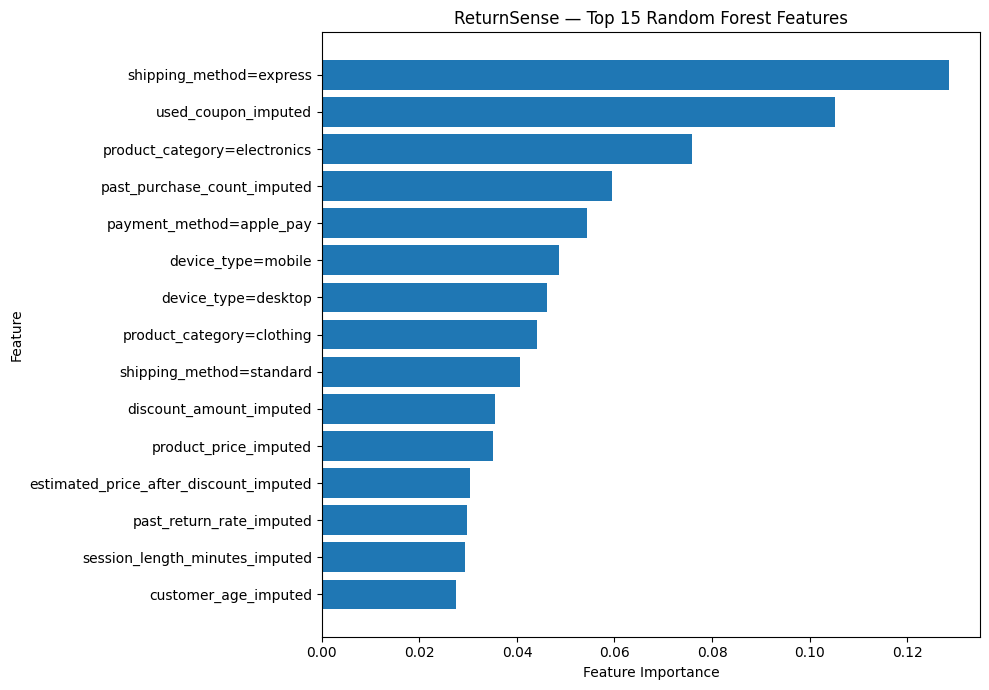

In [46]:

import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["feature"],
    top_features["importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("ReturnSense — Top 15 Random Forest Features")
plt.tight_layout()
plt.show()


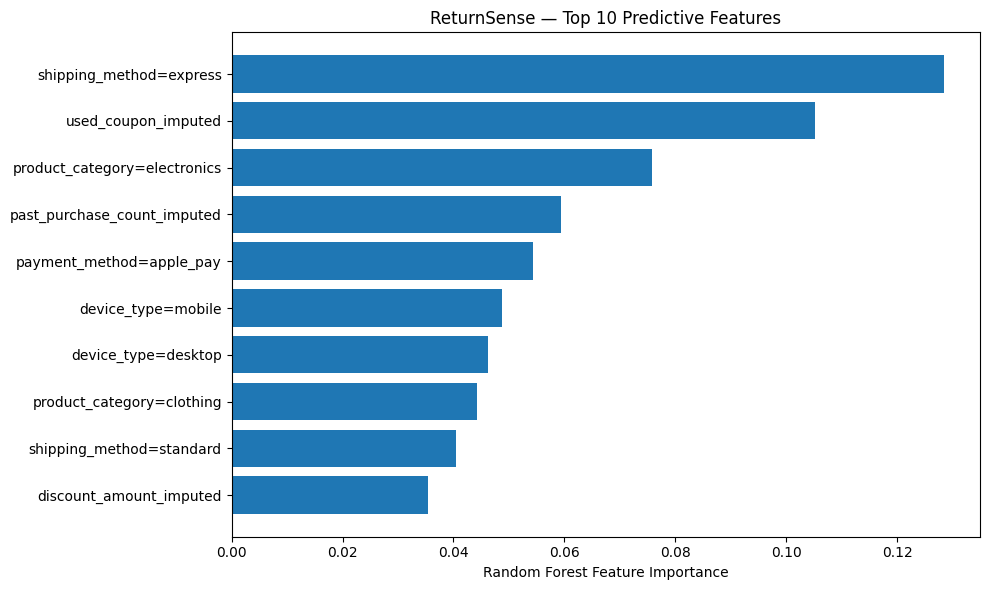

Top 10 feature importance chart saved.


In [47]:

import matplotlib.pyplot as plt

top10 = importance_df.head(10).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top10["feature"], top10["importance"])
plt.xlabel("Random Forest Feature Importance")
plt.title("ReturnSense — Top 10 Predictive Features")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/returnsense_top10_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Top 10 feature importance chart saved.")


In [48]:

def get_feature_group(feature):
    if "=" in feature:
        return feature.split("=")[0]
    return "numeric_or_engineered"

importance_df["feature_group"] = (
    importance_df["feature"].apply(get_feature_group)
)

group_importance = (
    importance_df.groupby("feature_group", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)

display(group_importance)


,feature_group,importance
1,numeric_or_engineered,0.460195
4,shipping_method,0.183830
3,product_category,0.167482
0,device_type,0.101518
2,payment_method,0.086975


In [49]:

# Original numeric features only
original_numeric_cols = [
    "customer_age",
    "product_price",
    "discount_percent",
    "product_rating",
    "past_purchase_count",
    "past_return_rate",
    "session_length_minutes",
    "num_product_views",
    "used_coupon"
]

# Rebuild preprocessing without engineered features
original_imputer = Imputer(
    inputCols=original_numeric_cols,
    outputCols=[f"{c}_original_imputed" for c in original_numeric_cols],
    strategy="median"
)

original_assembler = VectorAssembler(
    inputCols=[f"{c}_original_imputed" for c in original_numeric_cols]
              + [f"{c}_ohe" for c in categorical_cols],
    outputCol="features",
    handleInvalid="keep"
)

rf_original = RandomForestClassifier(
    featuresCol="features",
    labelCol="returned",
    numTrees=100,
    maxDepth=8,
    seed=42
)

original_pipeline = Pipeline(
    stages=indexers + [
        encoder,
        original_imputer,
        original_assembler,
        rf_original
    ]
)

rf_original_model = original_pipeline.fit(train_part)
rf_original_predictions = rf_original_model.transform(valid_part)

rf_original_auc = BinaryClassificationEvaluator(
    labelCol="returned",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(rf_original_predictions)

print(f"Random Forest with engineered features: {rf_auc:.4f}")
print(f"Random Forest with original features:   {rf_original_auc:.4f}")
print(f"Difference:                            {rf_auc - rf_original_auc:+.4f}")


26/10/27 08:34:08 WARN DAGScheduler: Broadcasting large task binary with size 1140.5 KiB
26/10/27 08:34:13 WARN DAGScheduler: Broadcasting large task binary with size 2.0 MiB
26/10/27 08:34:20 WARN DAGScheduler: Broadcasting large task binary with size 3.8 MiB
26/10/27 08:34:28 WARN DAGScheduler: Broadcasting large task binary with size 1027.7 KiB
26/10/27 08:34:30 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB


Random Forest with engineered features: 0.5923
Random Forest with original features:   0.5918
Difference:                            +0.0005


In [50]:

import pandas as pd

comparison_data = [
    {
        "Model": "Logistic Regression",
        "ROC-AUC": lr_auc_corrected
    },
    {
        "Model": "Random Forest",
        "ROC-AUC": rf_auc
    },
    {
        "Model": "Gradient-Boosted Trees",
        "ROC-AUC": gbt_auc
    }
]

comparison_df = pd.DataFrame(comparison_data)

comparison_df = comparison_df.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

comparison_df["Rank"] = range(1, len(comparison_df) + 1)

display(comparison_df[["Rank", "Model", "ROC-AUC"]])


,Rank,Model,ROC-AUC
0,1,Gradient-Boosted Trees,0.592821
1,2,Random Forest,0.592259
2,3,Logistic Regression,0.589718


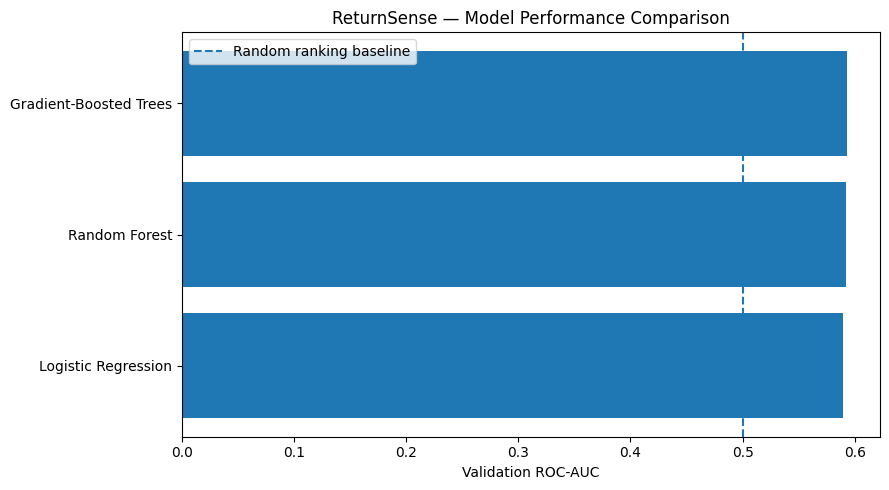

In [51]:


import os
import pandas as pd
import matplotlib.pyplot as plt

# Recreate model comparison data
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient-Boosted Trees"
    ],
    "ROC-AUC": [
        lr_auc_corrected,
        rf_auc,
        gbt_auc
    ]
})

comparison_df = comparison_df.sort_values(
    "ROC-AUC",
    ascending=True
)

# Ensure output directory exists
OUTPUT_DIR = "/kaggle/working/returnsense"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Plot comparison
plt.figure(figsize=(9, 5))

plt.barh(
    comparison_df["Model"],
    comparison_df["ROC-AUC"]
)

plt.axvline(
    x=0.5,
    linestyle="--",
    label="Random ranking baseline"
)

plt.xlabel("Validation ROC-AUC")
plt.ylabel("Model")
plt.title("ReturnSense — Model Performance Comparison")
plt.xlim(0.0, 1.0)
plt.legend()
plt.tight_layout()

chart_path = f"{OUTPUT_DIR}/returnsense_model_comparison.png"

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully:", chart_path)
display(comparison_df.sort_values("ROC-AUC", ascending=False))


In [62]:

from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
import pandas as pd

# Select the best model based on validation ROC-AUC
model_scores = [
    ("Logistic Regression", lr_auc_corrected),
    ("Random Forest", rf_auc),
    ("Gradient-Boosted Trees", gbt_auc)
]

best_model_name, best_auc = max(
    model_scores,
    key=lambda x: x[1]
)

if best_model_name == "Logistic Regression":
    best_predictions = lr_predictions
elif best_model_name == "Random Forest":
    best_predictions = rf_predictions
else:
    best_predictions = gbt_predictions

# Convert Spark probability vector into an array
best_predictions = best_predictions.withColumn(
    "probability_array",
    vector_to_array(F.col("probability"))
)

print("Selected model:", best_model_name)
print(f"Validation ROC-AUC: {best_auc:.4f}")

threshold_results = []

for threshold in [0.3, 0.4, 0.5, 0.6]:
    scored = best_predictions.withColumn(
        "custom_prediction",
        (F.col("probability_array")[1] >= threshold).cast("double")
    )

    tp = scored.filter(
        (F.col("custom_prediction") == 1) &
        (F.col("returned") == 1)
    ).count()

    fp = scored.filter(
        (F.col("custom_prediction") == 1) &
        (F.col("returned") == 0)
    ).count()

    fn = scored.filter(
        (F.col("custom_prediction") == 0) &
        (F.col("returned") == 1)
    ).count()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-score": round(f1, 4)
    })

display(pd.DataFrame(threshold_results))


Selected model: Gradient-Boosted Trees
Validation ROC-AUC: 0.5928


,Threshold,Precision,Recall,F1-score
0,0.3,0.4787,0.9885,0.6450
1,0.4,0.5052,0.8495,0.6336
2,0.5,0.5545,0.4444,0.4934
3,0.6,0.6339,0.1104,0.1880


In [63]:

risk_predictions = (
    best_predictions
    .withColumn(
        "return_probability",
        F.col("probability_array")[1]
    )
    .withColumn(
        "risk_level",
        F.when(F.col("return_probability") >= 0.70, "High")
         .when(F.col("return_probability") >= 0.40, "Medium")
         .otherwise("Low")
    )
)

risk_predictions.select(
    "order_id",
    "returned",
    "return_probability",
    "risk_level"
).show(10, truncate=False)


+--------+--------+------------------+----------+
|order_id|returned|return_probability|risk_level|
+--------+--------+------------------+----------+
|211358  |0       |0.4922387283063556|Medium    |
|235939  |0       |0.4095631386021088|Medium    |
|248355  |1       |0.3894576117670461|Low       |
|56794   |0       |0.3733017822835506|Low       |
|220359  |0       |0.5320413692400543|Medium    |
|122723  |1       |0.5170571726522935|Medium    |
|144043  |1       |0.6446116900224   |Medium    |
|32370   |1       |0.3238679369300751|Low       |
|127772  |1       |0.6340289227017453|Medium    |
|277     |0       |0.5048784852632466|Medium    |
+--------+--------+------------------+----------+
only showing top 10 rows


In [64]:

risk_summary = (
    risk_predictions
    .groupBy("risk_level")
    .agg(
        F.count("*").alias("order_count"),
        F.round(
            F.avg("return_probability"), 4
        ).alias("average_predicted_risk"),
        F.round(
            F.avg(F.col("returned").cast("double")), 4
        ).alias("actual_return_rate")
    )
    .orderBy(
        F.when(F.col("risk_level") == "High", 1)
         .when(F.col("risk_level") == "Medium", 2)
         .otherwise(3)
    )
)

risk_summary.show(truncate=False)


+----------+-----------+----------------------+------------------+
|risk_level|order_count|average_predicted_risk|actual_return_rate|
+----------+-----------+----------------------+------------------+
|High      |305        |0.7209                |0.7246            |
|Medium    |31531      |0.5038                |0.5031            |
|Low       |8064       |0.3536                |0.3533            |
+----------+-----------+----------------------+------------------+



In [65]:

total_orders = risk_predictions.count()
review_limit = int(total_orders * 0.20)

top_20_percent = (
    risk_predictions
    .orderBy(
        F.col("return_probability").desc(),
        F.col("order_id").asc()
    )
    .limit(review_limit)
)

total_returns = risk_predictions.filter(
    F.col("returned") == 1
).count()

captured_returns = top_20_percent.filter(
    F.col("returned") == 1
).count()

reviewed_orders = top_20_percent.count()

print("TOP 20% REVIEW ANALYSIS")
print("Total validation orders:", total_orders)
print("Orders reviewed:", reviewed_orders)
print("Actual returns captured:", captured_returns)

print(
    "Share of actual returns captured:",
    round(captured_returns / total_returns, 4)
    if total_returns else 0
)

print(
    "Return rate among reviewed orders:",
    round(captured_returns / reviewed_orders, 4)
    if reviewed_orders else 0
)


TOP 20% REVIEW ANALYSIS
Total validation orders: 39900
Orders reviewed: 7980
Actual returns captured: 4711
Share of actual returns captured: 0.2488
Return rate among reviewed orders: 0.5904


In [66]:

from pyspark.sql.window import Window

# Rank orders by predicted return probability
rank_window = Window.orderBy(
    F.col("return_probability").desc()
)

ranked_predictions = (
    risk_predictions
    .withColumn(
        "risk_rank",
        F.row_number().over(rank_window)
    )
)

total_orders = risk_predictions.count()
review_limit = int(total_orders * 0.20)

top_20_percent = ranked_predictions.filter(
    F.col("risk_rank") <= review_limit
)

total_returns = risk_predictions.filter(
    F.col("returned") == 1
).count()

captured_returns = top_20_percent.filter(
    F.col("returned") == 1
).count()

reviewed_orders = top_20_percent.count()

print("TOP 20% REVIEW ANALYSIS")
print("Total validation orders:", total_orders)
print("Orders reviewed:", reviewed_orders)
print("Actual returns captured:", captured_returns)

print(
    "Share of actual returns captured:",
    round(captured_returns / total_returns, 4)
    if total_returns else 0
)

print(
    "Return rate among reviewed orders:",
    round(captured_returns / reviewed_orders, 4)
    if reviewed_orders else 0
)


26/10/27 08:41:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:41:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:41:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:41:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:41:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:41:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


TOP 20% REVIEW ANALYSIS
Total validation orders: 39900
Orders reviewed: 7980
Actual returns captured: 4711
Share of actual returns captured: 0.2488
Return rate among reviewed orders: 0.5904


26/10/27 08:41:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 08:41:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


In [68]:

from pyspark.sql import functions as F

total_orders = risk_predictions.count()
review_limit = int(total_orders * 0.20)

# Select the highest-risk 20% of orders
top_20_percent = (
    risk_predictions
    .orderBy(
        F.col("return_probability").desc(),
        F.col("order_id").asc()
    )
    .limit(review_limit)
)

total_returns = (
    risk_predictions
    .filter(F.col("returned") == 1)
    .count()
)

captured_returns = (
    top_20_percent
    .filter(F.col("returned") == 1)
    .count()
)

reviewed_orders = top_20_percent.count()

print("TOP 20% REVIEW ANALYSIS")
print("Orders reviewed:", reviewed_orders)
print("Actual returns captured:", captured_returns)
print(
    "Share of all actual returns captured:",
    round(captured_returns / total_returns, 4)
    if total_returns else 0
)
print(
    "Return rate among reviewed orders:",
    round(captured_returns / reviewed_orders, 4)
    if reviewed_orders else 0
)


TOP 20% REVIEW ANALYSIS
Orders reviewed: 7980
Actual returns captured: 4711
Share of all actual returns captured: 0.2488
Return rate among reviewed orders: 0.5904


In [69]:

OUTPUT_DIR = "/kaggle/working/returnsense"

(
    risk_predictions
    .write
    .mode("overwrite")
    .parquet(f"{OUTPUT_DIR}/validation_risk_predictions")
)

print("Validation risk predictions saved successfully.")


Validation risk predictions saved successfully.


In [70]:

import os

OUTPUT_DIR = "/kaggle/working/returnsense"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_PATH = f"{OUTPUT_DIR}/best_returnsense_model"

# Save the complete fitted pipeline, including preprocessing
gbt_model.write().overwrite().save(MODEL_PATH)

print("Model saved successfully!")
print("Model:", best_model_name)
print("Validation ROC-AUC:", round(gbt_auc, 4))
print("Saved to:", MODEL_PATH)


Model saved successfully!
Model: Gradient-Boosted Trees
Validation ROC-AUC: 0.5928
Saved to: /kaggle/working/returnsense/best_returnsense_model


In [71]:

# Score the test data with the fitted GBT pipeline
test_predictions = gbt_model.transform(test_features)

from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

test_predictions = test_predictions.withColumn(
    "return_probability",
    vector_to_array(F.col("probability"))[1]
)

test_predictions.select(
    "order_id",
    "return_probability",
    "prediction"
).show(10, truncate=False)

print("Test prediction rows:", test_predictions.count())


+--------+-------------------+----------+
|order_id|return_probability |prediction|
+--------+-------------------+----------+
|38683   |0.48554566561789503|0.0       |
|64939   |0.5352411658158246 |1.0       |
|3954    |0.42114570708792076|0.0       |
|120374  |0.6216278470079302 |1.0       |
|172861  |0.42667914215524394|0.0       |
|149303  |0.6179814695565637 |1.0       |
|111626  |0.5885994962276604 |1.0       |
|164553  |0.4627374928290634 |0.0       |
|55779   |0.357097367842218  |0.0       |
|141990  |0.4094415808673594 |0.0       |
+--------+-------------------+----------+
only showing top 10 rows
Test prediction rows: 50000


In [72]:

(
    test_predictions
    .select(
        "order_id",
        "return_probability",
        "prediction"
    )
    .write
    .mode("overwrite")
    .parquet(f"{OUTPUT_DIR}/test_predictions")
)

print("Test predictions saved successfully!")


Test predictions saved successfully!


In [73]:

(
    test_predictions
    .select(
        "order_id",
        "return_probability",
        "prediction"
    )
    .coalesce(1)
    .write
    .mode("overwrite")
    .option("header", True)
    .csv(f"{OUTPUT_DIR}/test_predictions_csv")
)

print("Test prediction CSV export folder created.")


Test prediction CSV export folder created.


In [74]:

from pyspark.sql import functions as F

print("TEST PREDICTION QUALITY CHECK")
print("-" * 40)

print("Total prediction rows:", test_predictions.count())

print(
    "Distinct order IDs:",
    test_predictions.select("order_id").distinct().count()
)

print(
    "Missing probabilities:",
    test_predictions.filter(
        F.col("return_probability").isNull()
    ).count()
)

print(
    "Probabilities outside [0, 1]:",
    test_predictions.filter(
        (F.col("return_probability") < 0) |
        (F.col("return_probability") > 1)
    ).count()
)

test_predictions.select(
    F.min("return_probability").alias("min_probability"),
    F.avg("return_probability").alias("avg_probability"),
    F.max("return_probability").alias("max_probability")
).show()


TEST PREDICTION QUALITY CHECK
----------------------------------------
Total prediction rows: 50000
Distinct order IDs: 50000


Missing probabilities: 0


Probabilities outside [0, 1]: 0


+------------------+------------------+------------------+
|   min_probability|   avg_probability|   max_probability|
+------------------+------------------+------------------+
|0.1467381964246588|0.4747727176737624|0.8333081367897462|
+------------------+------------------+------------------+



In [75]:

print("SAMPLE SUBMISSION COLUMNS:")
print(submission_spark.columns)

print("\nSAMPLE SUBMISSION SCHEMA:")
submission_spark.printSchema()

print("\nSAMPLE SUBMISSION PREVIEW:")
submission_spark.show(5, truncate=False)

print("\nTEST DATA COLUMNS:")
print(test_spark.columns)


SAMPLE SUBMISSION COLUMNS:
['ID', 'returned']

SAMPLE SUBMISSION SCHEMA:
root
 |-- ID: integer (nullable = true)
 |-- returned: integer (nullable = true)


SAMPLE SUBMISSION PREVIEW:
+------+--------+
|ID    |returned|
+------+--------+
|38683 |0       |
|64939 |0       |
|3954  |0       |
|120374|0       |
|172861|0       |
+------+--------+
only showing top 5 rows

TEST DATA COLUMNS:
['customer_age', 'product_price', 'discount_percent', 'product_rating', 'past_purchase_count', 'past_return_rate', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'device_type', 'product_category', 'shipping_method', 'payment_method', 'used_coupon', 'order_id']


In [76]:

print("PREDICTED RETURN CLASS COUNTS:")

test_predictions.groupBy("prediction").count().orderBy(
    "prediction"
).show()

print("PREDICTED RETURN FRACTION:")

test_predictions.select(
    F.round(
        F.avg(F.col("prediction").cast("double")), 4
    ).alias("predicted_return_fraction")
).show()


PREDICTED RETURN CLASS COUNTS:


+----------+-----+
|prediction|count|
+----------+-----+
|       0.0|30919|
|       1.0|19081|
+----------+-----+

PREDICTED RETURN FRACTION:


+-------------------------+
|predicted_return_fraction|
+-------------------------+
|                   0.3816|
+-------------------------+



In [77]:

from pyspark.sql import functions as F

# Map test order IDs to the required submission ID column
predictions_for_submission = test_predictions.select(
    F.col("order_id").cast("int").alias("ID"),
    F.col("prediction").cast("int").alias("returned")
)

# Preserve the exact row order of the sample submission
# by joining predictions to its IDs
final_submission = (
    submission_spark.select("ID")
    .join(predictions_for_submission, on="ID", how="left")
    .select("ID", "returned")
)

# Validate the submission before exporting
print("Submission rows:", final_submission.count())

print(
    "Missing predictions:",
    final_submission.filter(F.col("returned").isNull()).count()
)

print(
    "Duplicate IDs:",
    final_submission.count()
    - final_submission.select("ID").distinct().count()
)

final_submission.groupBy("returned").count().show()

final_submission.show(10, truncate=False)


Submission rows: 50000


Missing predictions: 0
Duplicate IDs: 0


+--------+-----+
|returned|count|
+--------+-----+
|       1|19081|
|       0|30919|
+--------+-----+



+------+--------+
|ID    |returned|
+------+--------+
|38683 |0       |
|64939 |1       |
|3954  |0       |
|120374|1       |
|172861|0       |
|149303|1       |
|111626|1       |
|164553|0       |
|55779 |0       |
|141990|0       |
+------+--------+
only showing top 10 rows


In [78]:

OUTPUT_DIR = "/kaggle/working/returnsense"

(
    final_submission
    .coalesce(1)
    .write
    .mode("overwrite")
    .option("header", True)
    .csv(f"{OUTPUT_DIR}/submission_csv")
)

print("Submission CSV folder created:", f"{OUTPUT_DIR}/submission_csv")


Submission CSV folder created: /kaggle/working/returnsense/submission_csv


In [79]:

from pyspark.sql import functions as F

expected_rows = submission_spark.count()
actual_rows = final_submission.count()

missing_predictions = final_submission.filter(
    F.col("returned").isNull()
).count()

duplicate_ids = (
    final_submission.count()
    - final_submission.select("ID").distinct().count()
)

print("EXPECTED ROWS:", expected_rows)
print("ACTUAL ROWS:", actual_rows)
print("MISSING PREDICTIONS:", missing_predictions)
print("DUPLICATE IDS:", duplicate_ids)

if (
    actual_rows == expected_rows
    and missing_predictions == 0
    and duplicate_ids == 0
):
    print("VALIDATION PASSED — submission is ready to export.")
else:
    print("VALIDATION FAILED — do not submit yet.")


EXPECTED ROWS: 50000
ACTUAL ROWS: 50000
MISSING PREDICTIONS: 0
DUPLICATE IDS: 0
VALIDATION PASSED — submission is ready to export.


In [80]:

import os
import glob
import shutil

OUTPUT_DIR = "/kaggle/working/returnsense"
CSV_FOLDER = f"{OUTPUT_DIR}/submission_csv"
FINAL_CSV = "/kaggle/working/returnsense_submission.csv"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Write the submission to a Spark output folder
(
    final_submission
    .coalesce(1)
    .write
    .mode("overwrite")
    .option("header", True)
    .csv(CSV_FOLDER)
)

# Find Spark's generated CSV part file
csv_files = glob.glob(f"{CSV_FOLDER}/part-*.csv")

if len(csv_files) != 1:
    raise RuntimeError(
        f"Expected one CSV part file, found {len(csv_files)}"
    )

shutil.copy2(csv_files[0], FINAL_CSV)

print("Final CSV created:", FINAL_CSV)
print("File size (bytes):", os.path.getsize(FINAL_CSV))


Final CSV created: /kaggle/working/returnsense_submission.csv
File size (bytes): 428038


In [81]:

evaluation_summary = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Validation_ROC_AUC": lr_auc_corrected
    },
    {
        "Model": "Random Forest",
        "Validation_ROC_AUC": rf_auc
    },
    {
        "Model": "Gradient-Boosted Trees",
        "Validation_ROC_AUC": gbt_auc
    }
]).sort_values("Validation_ROC_AUC", ascending=False)

evaluation_summary.to_csv(
    f"{OUTPUT_DIR}/model_evaluation_summary.csv",
    index=False
)

display(evaluation_summary.round(4))

print("Model evaluation summary saved.")


,Model,Validation_ROC_AUC
2,Gradient-Boosted Trees,0.5928
1,Random Forest,0.5923
0,Logistic Regression,0.5897


Model evaluation summary saved.


In [82]:

import os

OUTPUT_DIR = "/kaggle/working/returnsense"

print("RETURNSENSE PROJECT ARTIFACTS")
print("-" * 40)

for root, dirs, files in os.walk(OUTPUT_DIR):
    for file in files:
        print(os.path.relpath(os.path.join(root, file), OUTPUT_DIR))

print("\nSubmission exists:",
      os.path.exists("/kaggle/working/returnsense_submission.csv"))

print("Feature importance chart exists:",
      os.path.exists(f"{OUTPUT_DIR}/returnsense_top10_importance.png"))

print("Model comparison chart exists:",
      os.path.exists(f"{OUTPUT_DIR}/returnsense_model_comparison.png"))


RETURNSENSE PROJECT ARTIFACTS
----------------------------------------
model_evaluation_summary.csv
returnsense_model_comparison.png
test_predictions/part-00000-b9f27986-7ea1-40ac-acaf-b9ea12521575-c000.snappy.parquet
test_predictions/.part-00001-b9f27986-7ea1-40ac-acaf-b9ea12521575-c000.snappy.parquet.crc
test_predictions/._SUCCESS.crc
test_predictions/_SUCCESS
test_predictions/.part-00000-b9f27986-7ea1-40ac-acaf-b9ea12521575-c000.snappy.parquet.crc
test_predictions/part-00001-b9f27986-7ea1-40ac-acaf-b9ea12521575-c000.snappy.parquet
test_clean/part-00000-02f4641d-8406-4406-908d-6ac69cfc52d5-c000.snappy.parquet
test_clean/part-00001-02f4641d-8406-4406-908d-6ac69cfc52d5-c000.snappy.parquet
test_clean/.part-00001-02f4641d-8406-4406-908d-6ac69cfc52d5-c000.snappy.parquet.crc
test_clean/.part-00000-02f4641d-8406-4406-908d-6ac69cfc52d5-c000.snappy.parquet.crc
test_clean/._SUCCESS.crc
test_clean/_SUCCESS
train_clean/.part-00001-25050ca7-d06c-4f05-8bcf-ff2d56814951-c000.snappy.parquet.crc
trai

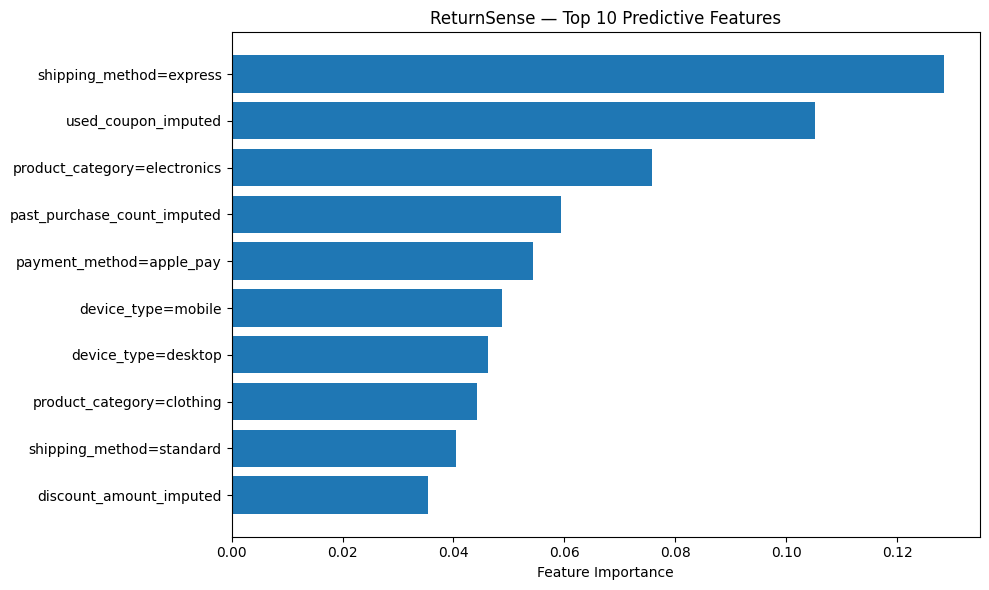

Saved: /kaggle/working/returnsense/returnsense_top10_importance.png


In [83]:

import os
import matplotlib.pyplot as plt

OUTPUT_DIR = "/kaggle/working/returnsense"
os.makedirs(OUTPUT_DIR, exist_ok=True)

top10 = importance_df.head(10).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top10["feature"], top10["importance"])
plt.xlabel("Feature Importance")
plt.title("ReturnSense — Top 10 Predictive Features")
plt.tight_layout()

importance_path = f"{OUTPUT_DIR}/returnsense_top10_importance.png"

plt.savefig(
    importance_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", importance_path)


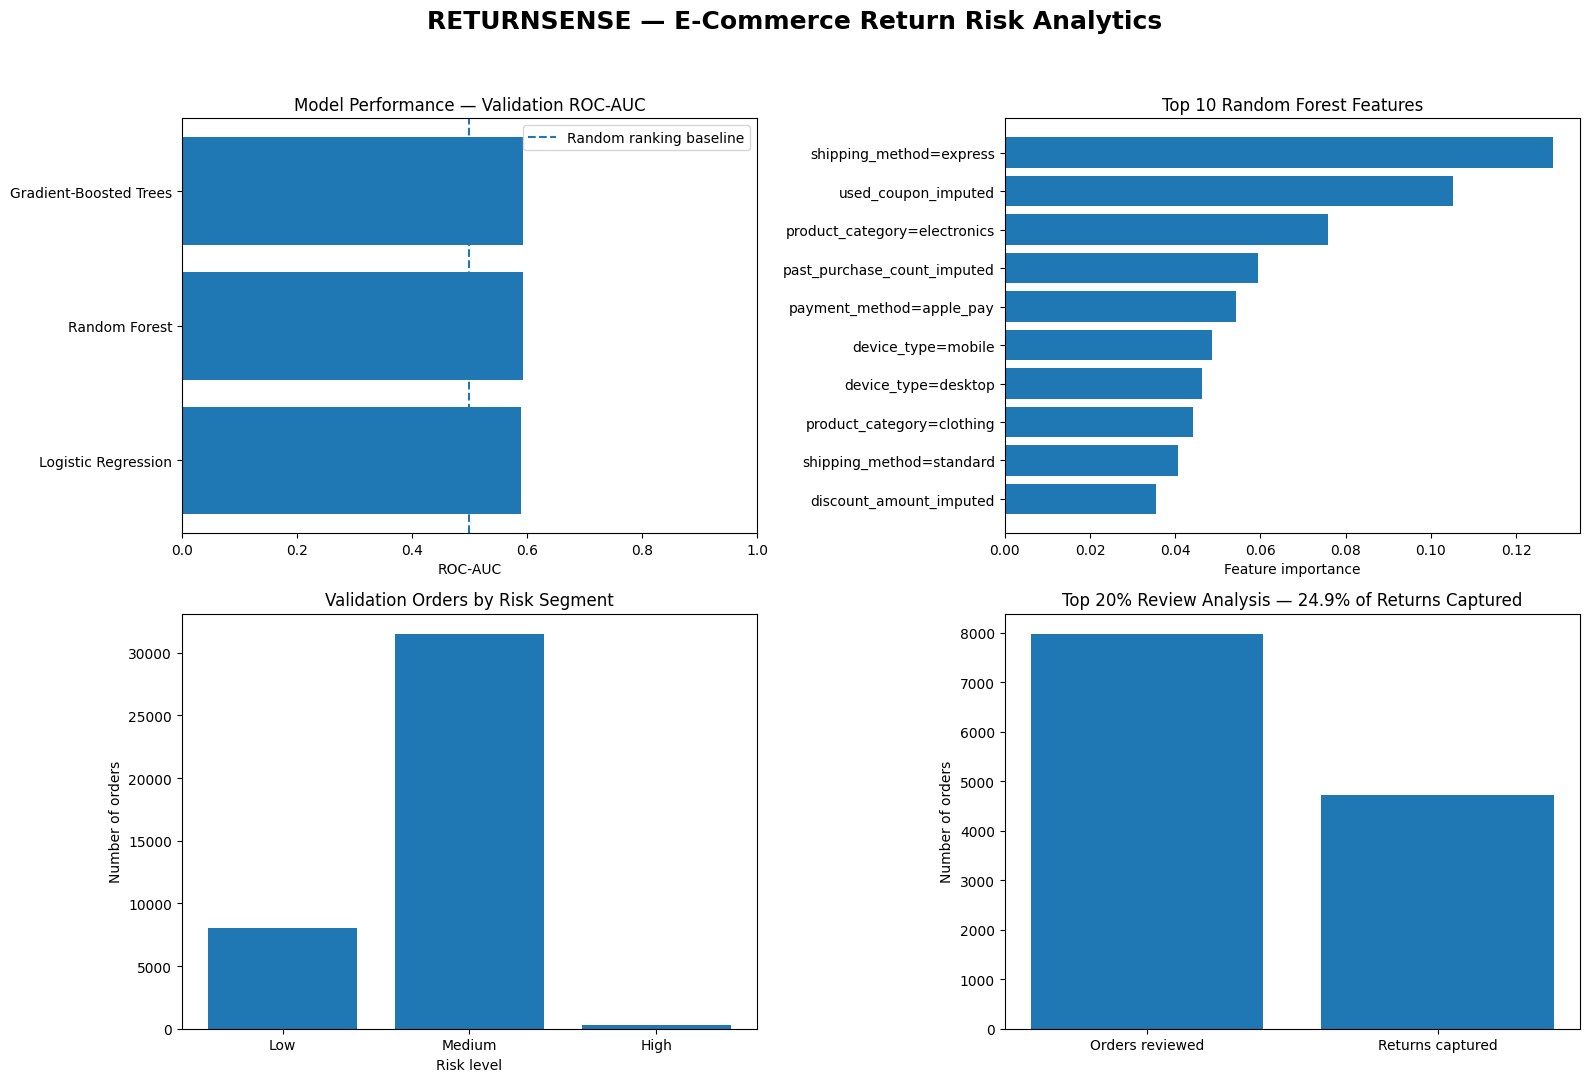

Dashboard saved: /kaggle/working/returnsense/returnsense_analytics_dashboard.png


In [84]:

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

# Model comparison
models_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient-Boosted Trees"
    ],
    "ROC_AUC": [
        lr_auc_corrected,
        rf_auc,
        gbt_auc
    ]
}).sort_values("ROC_AUC", ascending=True)

# Risk distribution from validation predictions
risk_counts = (
    risk_predictions
    .groupBy("risk_level")
    .count()
    .toPandas()
)

risk_order = ["Low", "Medium", "High"]
risk_counts["risk_level"] = pd.Categorical(
    risk_counts["risk_level"],
    categories=risk_order,
    ordered=True
)
risk_counts = risk_counts.sort_values("risk_level")

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Model comparison
axes[0, 0].barh(models_df["Model"], models_df["ROC_AUC"])
axes[0, 0].axvline(
    0.5,
    linestyle="--",
    label="Random ranking baseline"
)
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_title("Model Performance — Validation ROC-AUC")
axes[0, 0].set_xlabel("ROC-AUC")
axes[0, 0].legend()

# 2. Top 10 features
top10 = importance_df.head(10).sort_values(
    "importance",
    ascending=True
)
axes[0, 1].barh(top10["feature"], top10["importance"])
axes[0, 1].set_title("Top 10 Random Forest Features")
axes[0, 1].set_xlabel("Feature importance")

# 3. Validation risk distribution
axes[1, 0].bar(
    risk_counts["risk_level"].astype(str),
    risk_counts["count"]
)
axes[1, 0].set_title("Validation Orders by Risk Segment")
axes[1, 0].set_xlabel("Risk level")
axes[1, 0].set_ylabel("Number of orders")

# 4. Review analysis
reviewed_orders = 7980
captured_returns = 4711
capture_rate = captured_returns / 18933  # validation returns from earlier result

axes[1, 1].bar(
    ["Orders reviewed", "Returns captured"],
    [reviewed_orders, captured_returns]
)
axes[1, 1].set_title(
    f"Top 20% Review Analysis — {capture_rate:.1%} of Returns Captured"
)
axes[1, 1].set_ylabel("Number of orders")

fig.suptitle(
    "RETURNSENSE — E-Commerce Return Risk Analytics",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

dashboard_path = f"{OUTPUT_DIR}/returnsense_analytics_dashboard.png"

plt.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved:", dashboard_path)


In [85]:

total_validation_returns = risk_predictions.filter(
    F.col("returned") == 1
).count()

capture_rate = (
    captured_returns / total_validation_returns
    if total_validation_returns else 0
)

print("Actual validation returns:", total_validation_returns)
print(f"Top-20% return capture rate: {capture_rate:.2%}")


Actual validation returns: 18932
Top-20% return capture rate: 24.88%


In [86]:

from pyspark.sql import functions as F

print("=" * 60)
print("RETURNSENSE — FEATURE VALIDITY AUDIT")
print("=" * 60)

# 1. Compare train and test columns
train_cols = set(train_features.columns)
test_cols = set(test_features.columns)

print("\n1. Column differences")
print("Train-only columns:", sorted(train_cols - test_cols))
print("Test-only columns:", sorted(test_cols - train_cols))

# 2. Check the target distribution
print("\n2. Target distribution")
train_features.groupBy("returned").count().orderBy("returned").show()

# 3. Check historical features
print("\n3. Historical feature ranges")
train_features.select(
    F.min("past_purchase_count").alias("min_purchases"),
    F.max("past_purchase_count").alias("max_purchases"),
    F.min("past_return_rate").alias("min_return_rate"),
    F.max("past_return_rate").alias("max_return_rate")
).show()

# 4. Check delivery delay values
print("\n4. Delivery delay range")
train_features.select(
    F.min("delivery_delay_days").alias("min_delay"),
    F.max("delivery_delay_days").alias("max_delay"),
    F.sum(
        F.when(F.col("delivery_delay_days") < 0, 1).otherwise(0)
    ).alias("negative_delay_count")
).show()

# 5. Check invalid values that were replaced with NULL
print("\n5. Missing values after validation")
columns_to_check = [
    "product_price",
    "discount_percent",
    "product_rating",
    "num_product_views",
    "session_length_minutes"
]

train_features.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in columns_to_check
]).show()

# 6. Check IDs
print("\n6. ID uniqueness")
print(
    "Train distinct order IDs:",
    train_features.select("order_id").distinct().count()
)
print(
    "Test distinct order IDs:",
    test_features.select("order_id").distinct().count()
)


RETURNSENSE — FEATURE VALIDITY AUDIT

1. Column differences
Train-only columns: ['returned']
Test-only columns: []

2. Target distribution
+--------+------+
|returned| count|
+--------+------+
|       0|105081|
|       1| 94919|
+--------+------+


3. Historical feature ranges
+-------------+-------------+-------------------+------------------+
|min_purchases|max_purchases|    min_return_rate|   max_return_rate|
+-------------+-------------+-------------------+------------------+
|            1|           26|-0.0608784165936474|0.8664200331772883|
+-------------+-------------+-------------------+------------------+


4. Delivery delay range
+------------------+-----------------+--------------------+
|         min_delay|        max_delay|negative_delay_count|
+------------------+-----------------+--------------------+
|-9.049981182815271|7.961332516584129|               78564|
+------------------+-----------------+--------------------+


5. Missing values after validation
+-------------

In [88]:

print("Sample submission IDs:", submission_spark.count())
print("Test order IDs:", test_spark.count())

print(
    "Submission IDs matching test order IDs:",
    submission_spark.select(F.col("ID").alias("order_id"))
    .join(
        test_spark.select("order_id").distinct(),
        on="order_id",
        how="inner"
    )
    .count()
)

print("Sample submission preview:")
submission_spark.show(10, truncate=False)

print("Test order ID preview:")
test_spark.select("order_id").show(10, truncate=False)


Sample submission IDs: 50000
Test order IDs: 50000
Submission IDs matching test order IDs: 50000
Sample submission preview:
+------+--------+
|ID    |returned|
+------+--------+
|38683 |0       |
|64939 |0       |
|3954  |0       |
|120374|0       |
|172861|0       |
|149303|0       |
|111626|0       |
|164553|0       |
|55779 |0       |
|141990|0       |
+------+--------+
only showing top 10 rows
Test order ID preview:
+--------+
|order_id|
+--------+
|38683   |
|64939   |
|3954    |
|120374  |
|172861  |
|149303  |
|111626  |
|164553  |
|55779   |
|141990  |
+--------+
only showing top 10 rows
